# Gym Customer Churn Prediction — Model Fitness

### TripleTen Data Analyst Certification
### Luciana Jost

## Executive Summary

This project analyzes customer data from the Model Fitness gym chain to build a customer retention strategy. Overall, **26.5%** of the customers in this dataset churned (did not return the following month). Using a logistic regression model, churn can be predicted with **92.3% accuracy**, **85.4% precision**, and **82.8% recall**, slightly outperforming a random forest model on this dataset. The single strongest predictor of churn is **Lifetime** (how long the customer has been with the gym), followed by class attendance frequency and age. Clustering the customer base into 5 segments reveals two high-risk groups — customers who do not live or work near the gym, and new customers on short contracts with no partner or referral ties — and two low-risk groups, built around long (annual) contracts and consistent class attendance. These findings translate into concrete retention actions detailed in the conclusion.

## Project Objectives

- Learn to predict the probability of churn (for the next month) for each customer;
- Build typical user profiles: identify the most distinct customer groups and describe their main characteristics;
- Analyze the factors that impact churn the most;
- Draw conclusions and develop recommendations on how to improve customer service:
  - Identify target groups;
  - Suggest measures to reduce churn;
  - Describe any other patterns observed about customer interaction.

## Data Description

The dataset contains customer profile data for a given month, together with that month's churn flag. The columns are:

- `Churn` — churn for the month in question;
- `gender`;
- `Near_Location` — whether the customer lives or works in the neighborhood where the gym is located;
- `Partner` — whether the customer works at a partner company (the gym has corporate partners whose employees get discounts);
- `Promo_friends` — whether the customer originally signed up through a "bring a friend" offer;
- `Phone` — whether the customer provided a phone number;
- `Contract_period` — 1, 3, 6, or 12 months;
- `Group_visits` — whether the customer takes part in group sessions;
- `Age`;
- `Avg_additional_charges_total` — total amount spent on other gym services: cafe, sports goods, cosmetics, massages, etc.;
- `Month_to_end_contract` — months remaining until the contract expires;
- `Lifetime` — time (in months) since the customer's first visit to the gym;
- `Avg_class_frequency_total` — average weekly visit frequency over the customer's entire lifetime;
- `Avg_class_frequency_current_month` — average weekly visit frequency during the current month.

## 1. Loading the Data

We start by importing the libraries we'll need for the whole project and loading the dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage

RANDOM_STATE = 0
sns.set_style('whitegrid')

df = pd.read_csv('data/gym_churn_us.csv')
df.head()

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total          4000 non-null   float64
 12  Avg

The dataset has 4,000 rows and 14 columns, with no missing values, so no cleaning is needed before moving to the exploratory analysis.

## 2. Exploratory Data Analysis (EDA)

### 2.1 Descriptive statistics

We look at the mean, standard deviation, and quartiles of every feature with `describe()`.

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
gender,4000.0,0.510250,0.499957,0.000000,0.000000,1.000000,1.000000,1.000000
Near_Location,4000.0,0.845250,0.361711,0.000000,1.000000,1.000000,1.000000,1.000000
Partner,4000.0,0.486750,0.499887,0.000000,0.000000,0.000000,1.000000,1.000000
Promo_friends,4000.0,0.308500,0.461932,0.000000,0.000000,0.000000,1.000000,1.000000
Phone,4000.0,0.903500,0.295313,0.000000,1.000000,1.000000,1.000000,1.000000
Contract_period,4000.0,4.681250,4.549706,1.000000,1.000000,1.000000,6.000000,12.000000
Group_visits,4000.0,0.412250,0.492301,0.000000,0.000000,0.000000,1.000000,1.000000
Age,4000.0,29.184250,3.258367,18.000000,27.000000,29.000000,31.000000,41.000000
Avg_additional_charges_total,4000.0,146.943728,96.355602,0.148205,68.868830,136.220159,210.949625,552.590740
Month_to_end_contract,4000.0,4.322750,4.191297,1.000000,1.000000,1.000000,6.000000,12.000000


The average churn rate in this dataset is **26.5%**. Average customer age is about 29 years, the average contract length is close to 4.7 months, and the average lifetime with the gym is about 3.7 months, which already suggests a customer base where many relationships are fairly short.

### 2.2 Comparing customers who churned and customers who stayed

Next, we group the data by `Churn` and compare the average value of every feature between the two groups.

In [4]:
df.groupby('Churn').mean(numeric_only=True).T

Churn,0,1
gender,0.510037,0.510839
Near_Location,0.873086,0.768143
Partner,0.534195,0.355325
Promo_friends,0.353522,0.183789
Phone,0.903709,0.902922
Contract_period,5.747193,1.728558
Group_visits,0.464103,0.268615
Age,29.976523,26.989632
Avg_additional_charges_total,158.445715,115.082899
Month_to_end_contract,5.283089,1.662582


A few patterns stand out immediately:

- Churned customers have a much shorter **Contract_period** (1.7 months on average, versus 5.7 for retained customers) and a much shorter **Lifetime** (1.0 month versus 4.7 months);
- They attend less often, both over their whole lifetime and in the current month (`Avg_class_frequency_total` and `Avg_class_frequency_current_month` are both noticeably lower);
- They are less likely to live or work near the gym (`Near_Location`), less likely to come from a partner company, and less likely to have joined through a friend's referral;
- They are, on average, about 3 years younger and spend less on additional services.

In short, churn looks tied to short commitment (short contracts, short lifetime) and low engagement (fewer visits, fewer group classes), more than to any demographic factor like gender.

### 2.3 Feature distributions by churn

We now plot bar histograms for each feature, split by churn, to see these differences visually.

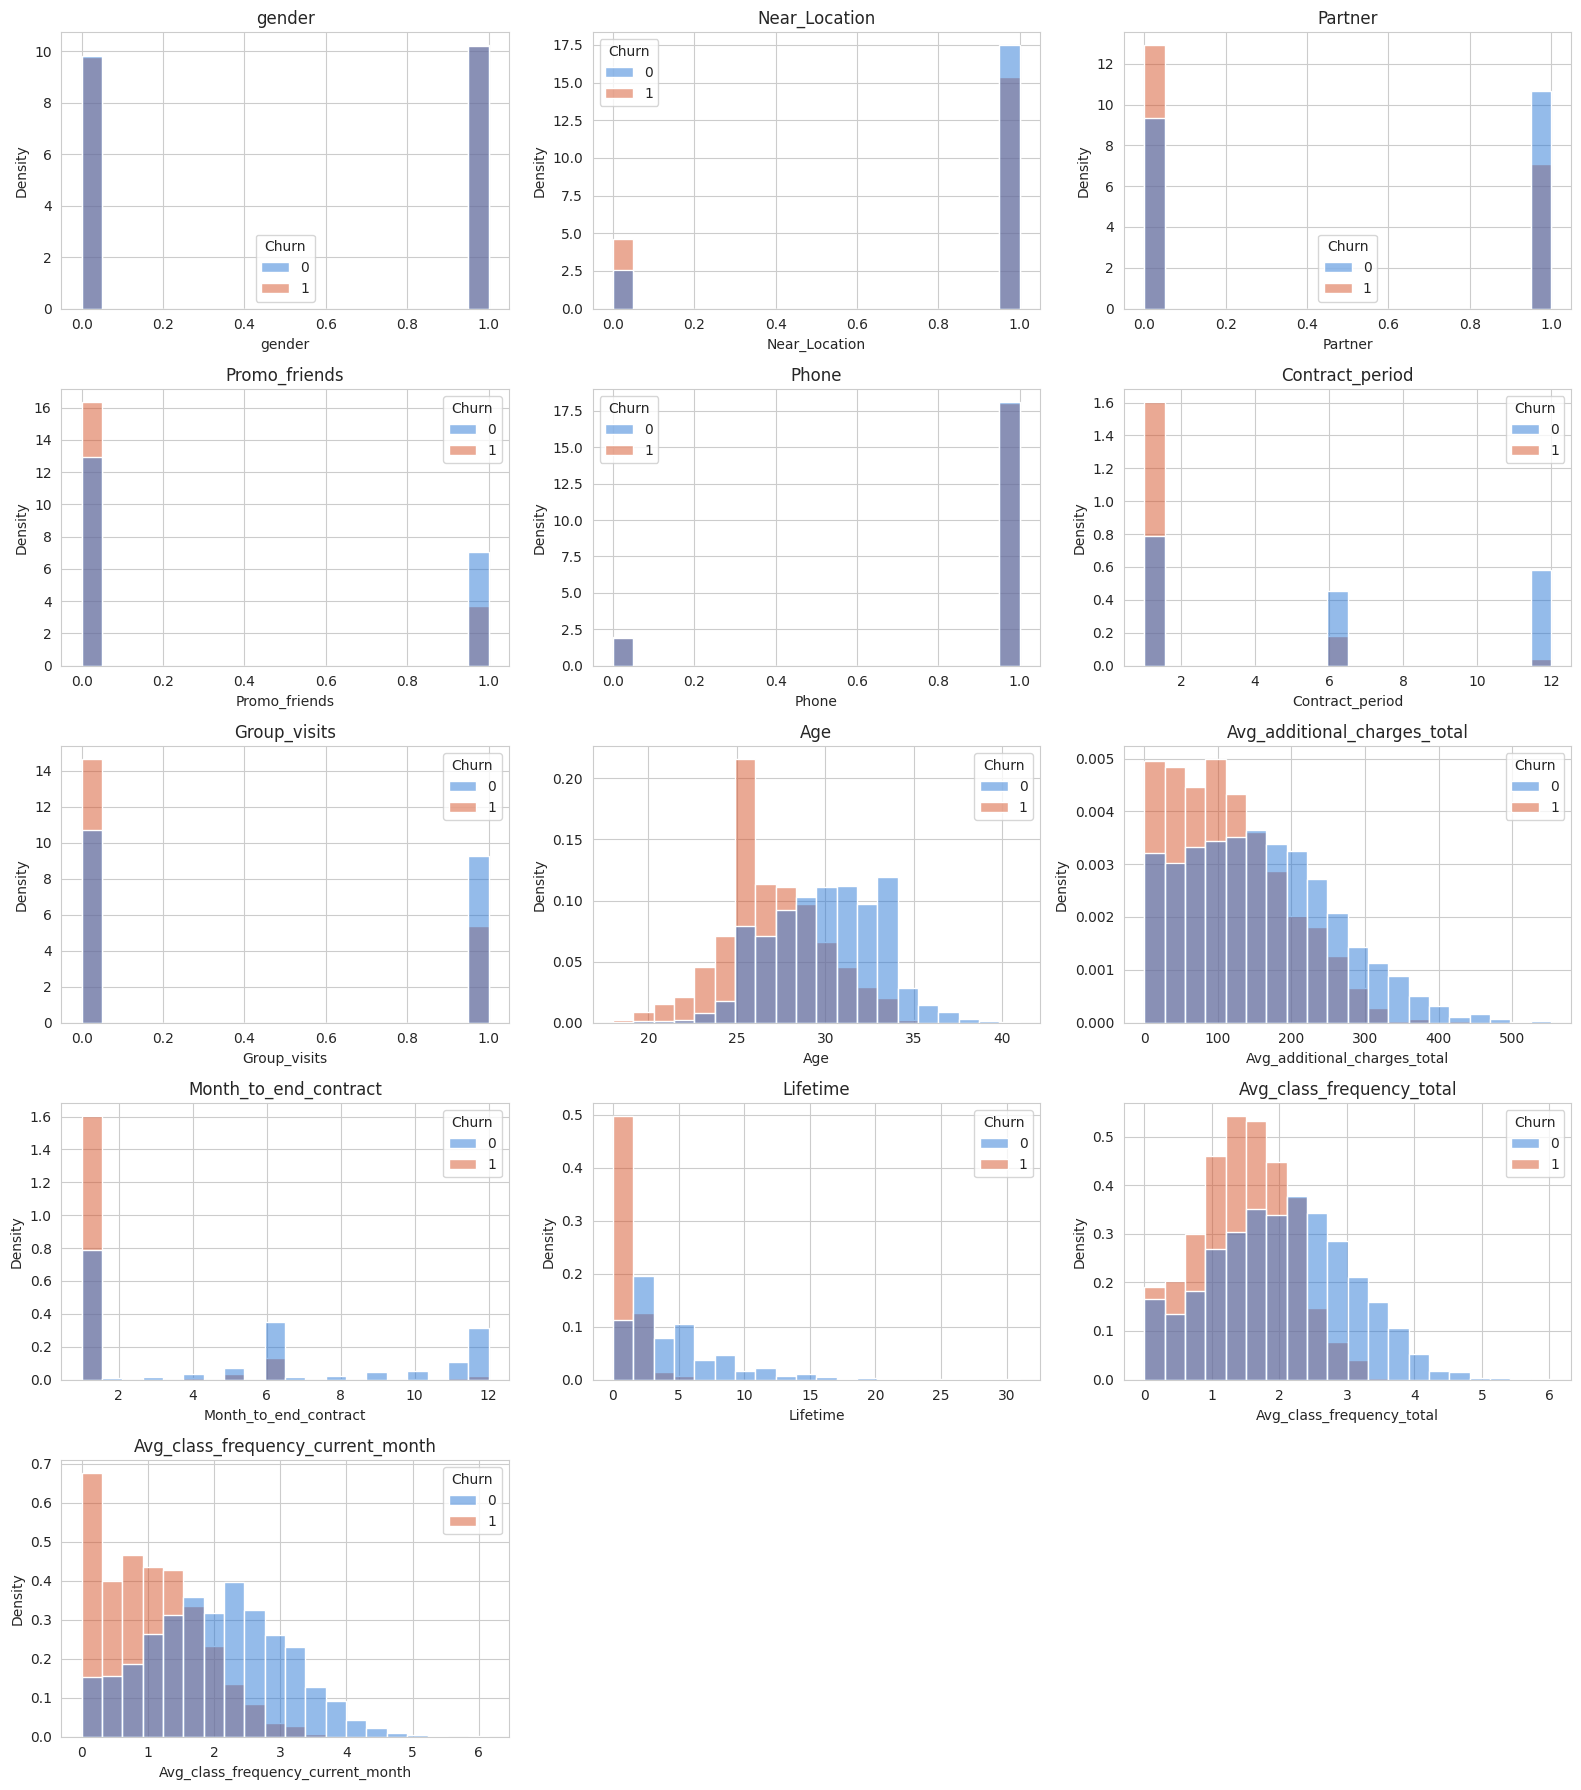

In [5]:
features = [c for c in df.columns if c != 'Churn']
fig, axes = plt.subplots(5, 3, figsize=(16, 18))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.histplot(data=df, x=col, hue='Churn', bins=20, stat='density',
                 common_norm=False, alpha=0.5, ax=axes[i], palette=['#2a78d6', '#d6542a'])
    axes[i].set_title(col)
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig('fig_distributions.png', dpi=110)
plt.show()

The clearest separations between churned (orange) and retained (blue) customers show up in `Lifetime`, `Contract_period`, `Month_to_end_contract`, and the two class frequency columns: churned customers are concentrated at the low end of all of these. Features like `gender` and `Phone` show almost no separation between the two groups, confirming they are not meaningful churn drivers.

### 2.4 Correlation matrix

Finally, we build and display the correlation matrix for all features.

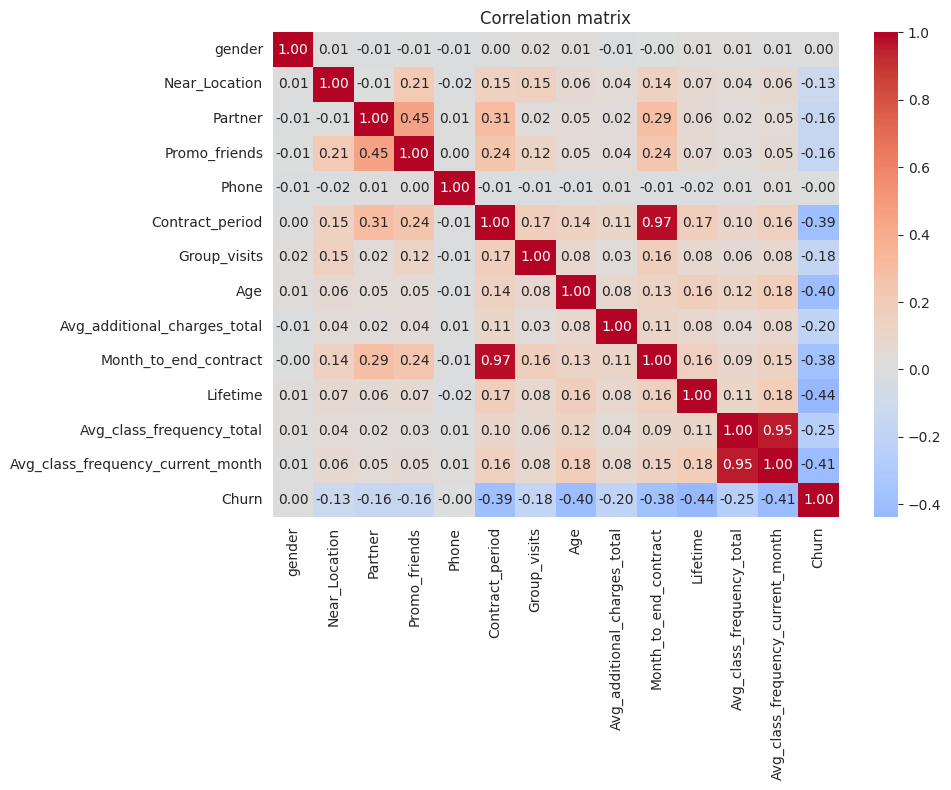

In [6]:
plt.figure(figsize=(10, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.tight_layout()
plt.savefig('fig_correlation.png', dpi=110)
plt.show()

`Avg_class_frequency_total` and `Avg_class_frequency_current_month` are very strongly correlated with each other (as expected, since one is a subset of the other), and `Contract_period` is strongly correlated with `Month_to_end_contract`. `Churn` correlates most negatively with `Lifetime`, `Avg_class_frequency_current_month`, and `Contract_period`, consistent with what we saw in the group comparison above.

## 3. Building a Model to Predict Customer Churn

We'll build a binary classification model where the target variable is whether the customer churns next month. We train two models — logistic regression and random forest — and compare them using accuracy, precision, and recall on a held-out validation set.

### 3.1 Train/validation split

In [7]:
X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f'Train set: {X_train.shape[0]} rows | Validation set: {X_valid.shape[0]} rows')

Train set: 3200 rows | Validation set: 800 rows


### 3.2 Logistic Regression

Logistic regression is sensitive to feature scale, so we standardize the features before fitting it.

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

model_lr = LogisticRegression(random_state=RANDOM_STATE)
model_lr.fit(X_train_scaled, y_train)
pred_lr = model_lr.predict(X_valid_scaled)

acc_lr = accuracy_score(y_valid, pred_lr)
prec_lr = precision_score(y_valid, pred_lr)
rec_lr = recall_score(y_valid, pred_lr)
print(f'Logistic Regression — Accuracy: {acc_lr:.3f} | Precision: {prec_lr:.3f} | Recall: {rec_lr:.3f}')

Logistic Regression — Accuracy: 0.922 | Precision: 0.854 | Recall: 0.828


### 3.3 Random Forest

Tree-based models don't require feature scaling, so we fit the random forest on the original (unscaled) features.

In [9]:
model_rf = RandomForestClassifier(random_state=RANDOM_STATE)
model_rf.fit(X_train, y_train)
pred_rf = model_rf.predict(X_valid)

acc_rf = accuracy_score(y_valid, pred_rf)
prec_rf = precision_score(y_valid, pred_rf)
rec_rf = recall_score(y_valid, pred_rf)
print(f'Random Forest — Accuracy: {acc_rf:.3f} | Precision: {prec_rf:.3f} | Recall: {rec_rf:.3f}')

Random Forest — Accuracy: 0.916 | Precision: 0.839 | Recall: 0.818


### 3.4 Comparing the models

In [10]:
comparison = pd.DataFrame({
    'Logistic Regression': [acc_lr, prec_lr, rec_lr],
    'Random Forest': [acc_rf, prec_rf, rec_rf],
}, index=['Accuracy', 'Precision', 'Recall'])
comparison

,Logistic Regression,Random Forest
Accuracy,0.922500,0.916250
Precision,0.854167,0.839378
Recall,0.828283,0.818182


Logistic regression slightly outperforms the random forest on all three metrics on this validation set (92.3% vs 91.6% accuracy, 85.4% vs 83.9% precision, 82.8% vs 81.8% recall). Since the difference is small and logistic regression is also simpler and easier to explain to the business, **logistic regression is the recommended model** for this churn-prediction task.

We also look at which features the random forest considers most important, since this gives an independent check on which factors drive churn.

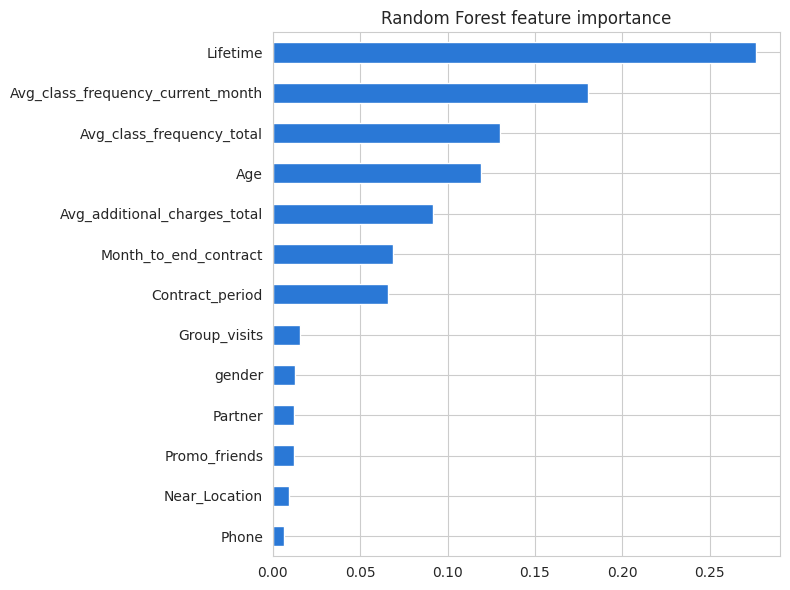

Lifetime                             0.276499
Avg_class_frequency_current_month    0.180170
Avg_class_frequency_total            0.129883
Age                                  0.119129
Avg_additional_charges_total         0.091473
Month_to_end_contract                0.068855
Contract_period                      0.065964
Group_visits                         0.015652
gender                               0.012425
Partner                              0.012285
Promo_friends                        0.012053
Near_Location                        0.009421
Phone                                0.006192
dtype: float64

In [11]:
importances = pd.Series(model_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
importances.plot(kind='barh', color='#2a78d6')
plt.gca().invert_yaxis()
plt.title('Random Forest feature importance')
plt.tight_layout()
plt.savefig('fig_importance.png', dpi=110)
plt.show()
importances

`Lifetime` is by far the most important feature, followed by the two class-frequency columns and `Age`. This matches the patterns we already saw in the EDA: how long someone has been a customer, and how often they actually show up, are the two strongest signals of whether they're about to leave.

## 4. Customer Clustering

Now we group customers into segments based on their characteristics (excluding the `Churn` column itself), to build user profiles the gym can act on.

### 4.1 Standardizing the data

In [12]:
X_cluster = df.drop('Churn', axis=1)
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

### 4.2 Hierarchical clustering and dendrogram

We build the distance matrix with `linkage()` and plot the resulting dendrogram to get a sense of how many clusters make sense for this data.

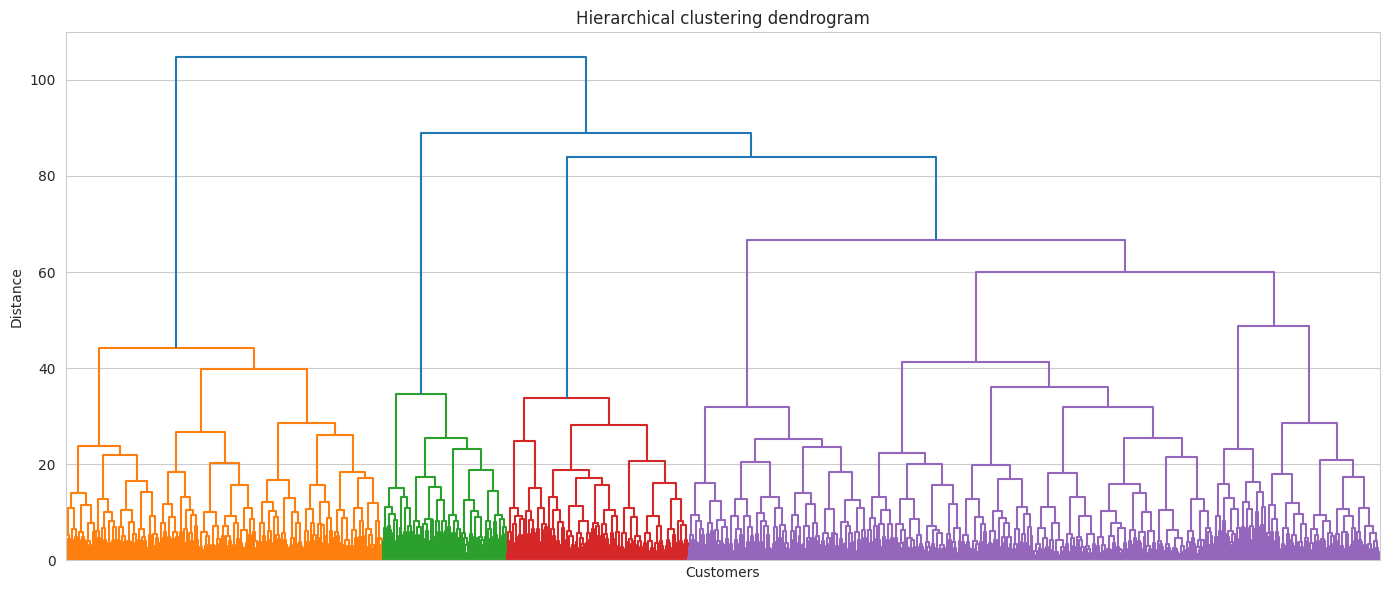

In [13]:
linked = linkage(X_cluster_scaled, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(linked, no_labels=True)
plt.title('Hierarchical clustering dendrogram')
plt.xlabel('Customers')
plt.ylabel('Distance')
plt.tight_layout()
plt.savefig('fig_dendrogram.png', dpi=110)
plt.show()

The dendrogram supports splitting the customers into somewhere between 4 and 6 clearly separated clusters. We'll move forward with **n=5** clusters using K-Means, which also sits comfortably within that range.

### 4.3 K-Means clustering (n=5)

In [14]:
km = KMeans(n_clusters=5, random_state=RANDOM_STATE)
df['cluster'] = km.fit_predict(X_cluster_scaled)
df['cluster'].value_counts().sort_index()

cluster
0    1138
1     746
2     941
3     631
4     544
Name: count, dtype: int64

### 4.4 Cluster profiles

We look at the average value of every feature within each cluster.

In [15]:
cluster_profile = df.groupby('cluster').mean(numeric_only=True).round(2)
cluster_profile.T

cluster,0,1,2,3,4
gender,0.49,0.59,0.50,0.48,0.50
Near_Location,1.00,0.97,0.94,1.00,0.00
Partner,0.24,0.29,0.74,0.80,0.47
Promo_friends,0.01,0.12,0.49,1.00,0.08
Phone,0.90,0.90,0.90,0.91,0.92
Contract_period,1.98,2.90,11.87,3.08,2.21
Group_visits,0.33,0.48,0.55,0.45,0.22
Age,28.24,30.34,29.91,29.05,28.48
Avg_additional_charges_total,130.88,164.19,165.15,139.86,133.63
Month_to_end_contract,1.90,2.65,10.85,2.87,2.07


### 4.5 Feature distributions by cluster

/tmp/ipykernel_583/2944643897.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='cluster', y=col, ax=axes[i], palette='viridis')
/tmp/ipykernel_583/2944643897.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='cluster', y=col, ax=axes[i], palette='viridis')
/tmp/ipykernel_583/2944643897.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='cluster', y=col, ax=axes[i], palette='viridis')
/tmp/ipykernel_583/2944643897.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be 

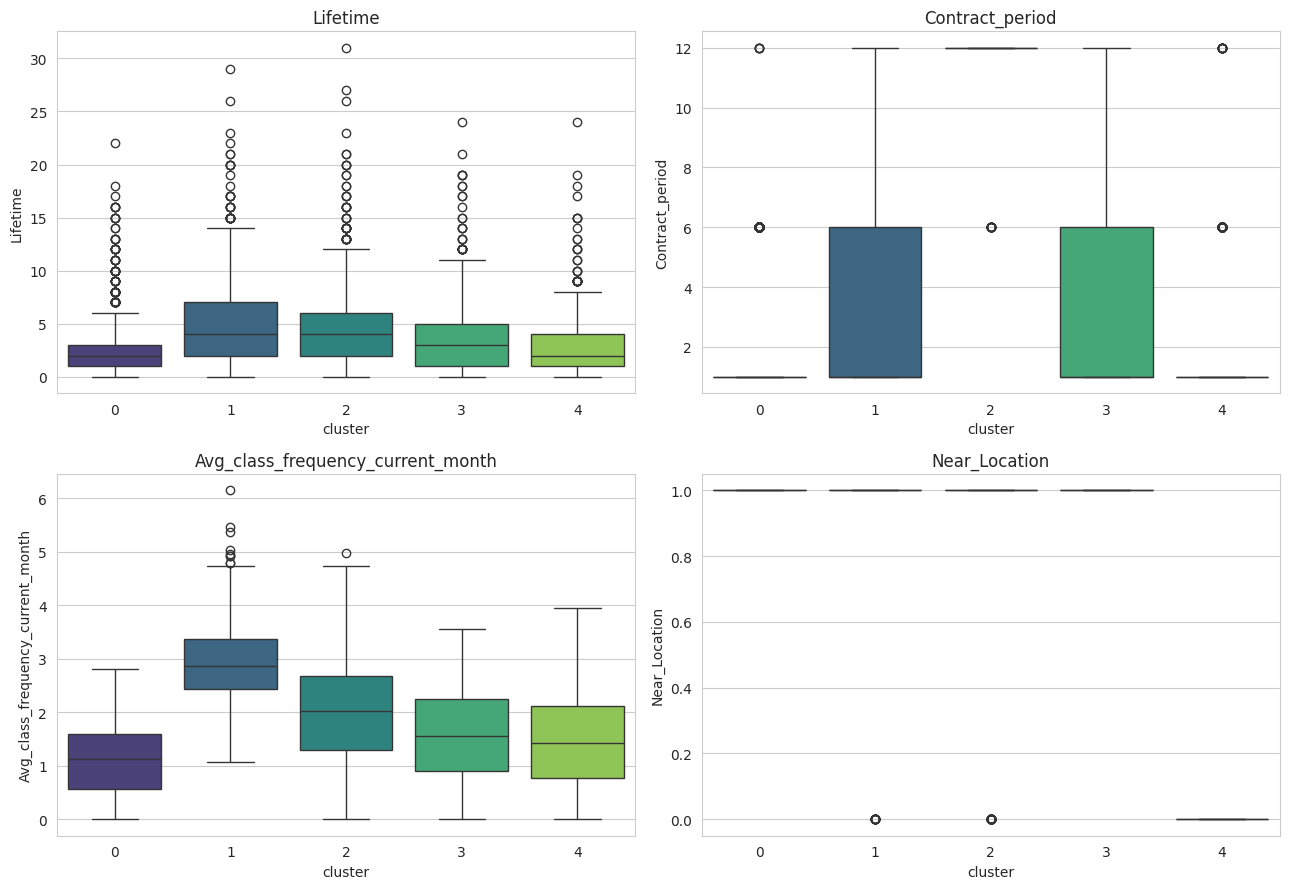

In [16]:
plot_features = ['Lifetime', 'Contract_period', 'Avg_class_frequency_current_month', 'Near_Location']
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()
for i, col in enumerate(plot_features):
    sns.boxplot(data=df, x='cluster', y=col, ax=axes[i], palette='viridis')
    axes[i].set_title(col)
plt.tight_layout()
plt.savefig('fig_cluster_distributions.png', dpi=110)
plt.show()

### 4.6 Churn rate by cluster

/tmp/ipykernel_583/3594915310.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=churn_by_cluster.reset_index(), x='cluster', y='churn_rate',


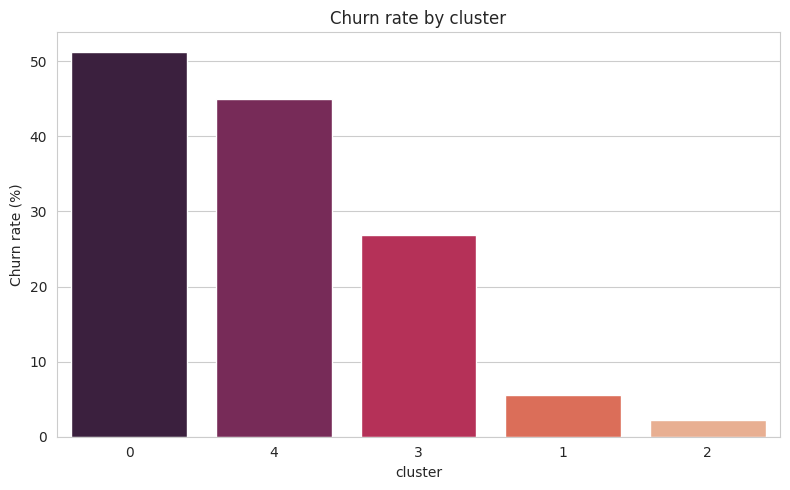

,churn_rate,count
cluster,,
0,51.3,1138
4,45.0,544
3,26.9,631
1,5.5,746
2,2.2,941


In [17]:
churn_by_cluster = df.groupby('cluster')['Churn'].agg(['mean', 'count']).rename(columns={'mean': 'churn_rate'})
churn_by_cluster['churn_rate'] = (churn_by_cluster['churn_rate'] * 100).round(1)
churn_by_cluster = churn_by_cluster.sort_values('churn_rate', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=churn_by_cluster.reset_index(), x='cluster', y='churn_rate',
            order=churn_by_cluster.index, palette='rocket')
plt.ylabel('Churn rate (%)')
plt.title('Churn rate by cluster')
plt.tight_layout()
plt.savefig('fig_churn_by_cluster.png', dpi=110)
plt.show()
churn_by_cluster

The five clusters split clearly into high-risk and low-risk groups:

- **Cluster 0 (1,138 customers, 51.3% churn — highest risk).** All live or work near the gym (`Near_Location` = 100%), but almost none came through a partner company or a friend's referral, contracts are short (~2 months), lifetime is short (~2.5 months), and class attendance is the lowest of all clusters. These are essentially new, low-engagement, low-commitment customers with no relationship anchor beyond proximity.
- **Cluster 4 (544 customers, 45.0% churn — second highest risk).** The defining trait is `Near_Location` = 0%: this is the one segment that does **not** live or work near the gym. Despite moderate partner ties, the lack of proximity alone appears to be a major churn driver.
- **Cluster 3 (631 customers, 26.9% churn — close to the overall average).** 100% joined through `Promo_friends` and 80% are tied to a partner company, yet churn is still meaningfully above the two low-risk clusters below. This shows that a referral or partner discount on its own is not enough to guarantee retention without follow-up engagement.
- **Cluster 1 (746 customers, 5.5% churn — low risk).** The highest class attendance of any cluster (close to 3 visits/week, both overall and in the current month) and a solid average lifetime (~5.2 months). Highly engaged, loyal customers.
- **Cluster 2 (941 customers, 2.2% churn — lowest risk).** Almost all on long, ~12-month contracts (`Contract_period` ≈ 11.9, `Month_to_end_contract` ≈ 10.9), with the highest share of partner-company and referral customers. Long contracts combined with a partner or referral relationship produce by far the strongest retention in the dataset.

## 5. Conclusions and Recommendations

**Main conclusions**

1. **Commitment length is the single strongest churn signal.** Both the model's feature importances and the cluster profiles point to `Lifetime` and `Contract_period` as the two biggest differentiators between customers who stay and customers who leave. Short-contract, short-tenure customers (Cluster 0) have the highest churn of any segment (51.3%).
2. **Engagement matters as much as tenure.** Class attendance frequency is the second most important predictor. The lowest-churn cluster (Cluster 1) is defined by high attendance, not by contract length or referral status.
3. **Proximity is a real, separate risk factor.** Customers who don't live or work near the gym (Cluster 4) churn at 45%, even though other characteristics are close to average. This is a structural barrier, not a motivation problem.
4. **A referral or partner discount alone is not protection against churn.** Cluster 3 shows that 100% "bring a friend" customers still churn at nearly the dataset average (26.9%) when they're not also on long contracts or highly engaged. The strongest retention (Cluster 2, 2.2% churn) only shows up when a partner/referral relationship is paired with a long contract.

**Recommendations**

- **Target group 1 — new, short-contract customers (Cluster 0 profile).** Build a structured first-60-days onboarding program (a welcome class schedule, a check-in call or message if attendance drops) specifically for customers on 1-month contracts with no partner or referral tie, since this is the group with both the lowest engagement and the highest churn.
- **Target group 2 — customers who live or work far from the gym (Cluster 4 profile).** Since proximity itself drives churn, consider flexible scheduling, a satellite class format, or a loyalty incentive (e.g., a free guest pass or discounted parking) specifically aimed at this group, rather than treating them the same as nearby customers.
- **Convert short contracts into long ones.** Offer a clear incentive (discount, bonus class pack, or locked-in rate) for moving from a 1-month to a 6- or 12-month contract, especially for customers who are already attending regularly, since Cluster 2 shows this combination nearly eliminates churn.
- **Make group classes part of the onboarding flow, not an opt-in extra.** Retained customers have far higher `Group_visits` participation than churned ones; proactively enrolling new members in at least one group session in their first weeks could help build the habit that keeps them coming back.
- **Don't rely on "bring a friend" promotions alone.** Pair referral sign-ups with the same onboarding and engagement follow-up used for Target group 1, since referral status by itself did not protect Cluster 3 from above-average churn.